In [ ]:
import pandas as pd

# Load Plant 1 Generation Data
plant_1_generation_df = pd.read_csv('/content/Plant_1_Generation_Data.csv')
print('Plant 1 Generation Data:')
display(plant_1_generation_df.head())

Plant 1 Generation Data:


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


In [ ]:
# Load Plant 1 Weather Sensor Data
plant_1_weather_df = pd.read_csv('/content/Plant_1_Weather_Sensor_Data.csv')
print('Plant 1 Weather Sensor Data:')
display(plant_1_weather_df.head())

Plant 1 Weather Sensor Data:


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


In [ ]:
# Convert 'DATE_TIME' column to datetime objects for both DataFrames
plant_1_generation_df['DATE_TIME'] = pd.to_datetime(plant_1_generation_df['DATE_TIME'], format='%d-%m-%Y %H:%M')
plant_1_weather_df['DATE_TIME'] = pd.to_datetime(plant_1_weather_df['DATE_TIME'], format='%Y-%m-%d %H:%M:%S')

print("Plant 1 Generation Data Info:")
plant_1_generation_df.info()
print("\nMissing values in Plant 1 Generation Data:")
print(plant_1_generation_df.isnull().sum())

print("\nPlant 1 Weather Sensor Data Info:")
plant_1_weather_df.info()
print("\nMissing values in Plant 1 Weather Sensor Data:")
print(plant_1_weather_df.isnull().sum())

Plant 1 Generation Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68778 entries, 0 to 68777
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   DATE_TIME    68778 non-null  datetime64[ns]
 1   PLANT_ID     68778 non-null  int64         
 2   SOURCE_KEY   68778 non-null  object        
 3   DC_POWER     68778 non-null  float64       
 4   AC_POWER     68778 non-null  float64       
 5   DAILY_YIELD  68778 non-null  float64       
 6   TOTAL_YIELD  68778 non-null  float64       
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 3.7+ MB

Missing values in Plant 1 Generation Data:
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64

Plant 1 Weather Sensor Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3182 entries, 0 to 3181
Data columns (total 6 columns):
 #   Column            

In [ ]:
# Set 'DATE_TIME' as index for both DataFrames
plant_1_generation_df_indexed = plant_1_generation_df.set_index('DATE_TIME')
plant_1_weather_df_indexed = plant_1_weather_df.set_index('DATE_TIME')

# Resample generation data to hourly and sum AC_POWER and DC_POWER
# We'll drop SOURCE_KEY before resampling as it's inverter-specific and we're aggregating per plant
# And also drop DAILY_YIELD and TOTAL_YIELD as they are cumulative and require different aggregation logic
plant_1_generation_hourly = plant_1_generation_df_indexed.drop(columns=['SOURCE_KEY', 'DAILY_YIELD', 'TOTAL_YIELD']).resample('h').sum()

# Resample weather data to hourly and take the mean of temperature and irradiation
# SOURCE_KEY is constant for plant weather data, so it can be dropped after setting index
plant_1_weather_hourly = plant_1_weather_df_indexed.drop(columns=['SOURCE_KEY']).resample('h').mean()

print("Hourly Plant 1 Generation Data (first 5 rows):")
display(plant_1_generation_hourly.head())

print("\nHourly Plant 1 Weather Sensor Data (first 5 rows):")
display(plant_1_weather_hourly.head())

Hourly Plant 1 Generation Data (first 5 rows):


,PLANT_ID,DC_POWER,AC_POWER
DATE_TIME,,,
2020-05-15 00:00:00,347340084,0.0,0.0
2020-05-15 01:00:00,355610086,0.0,0.0
2020-05-15 02:00:00,347340084,0.0,0.0
2020-05-15 03:00:00,347340084,0.0,0.0
2020-05-15 04:00:00,359745087,0.0,0.0



Hourly Plant 1 Weather Sensor Data (first 5 rows):


,PLANT_ID,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
DATE_TIME,,,,
2020-05-15 00:00:00,4135001.0,25.012697,22.643083,0.0
2020-05-15 01:00:00,4135001.0,24.667328,22.411960,0.0
2020-05-15 02:00:00,4135001.0,24.986837,23.512072,0.0
2020-05-15 03:00:00,4135001.0,24.954589,24.126433,0.0
2020-05-15 04:00:00,4135001.0,24.276670,22.133106,0.0


In [ ]:
# Merge the hourly generation and weather dataframes on their index (DATE_TIME)
merged_plant_1_data = pd.merge(plant_1_generation_hourly, plant_1_weather_hourly, left_index=True, right_index=True, how='inner')

print("Merged Plant 1 Hourly Data (first 5 rows):")
display(merged_plant_1_data.head())

print("\nMerged Plant 1 Hourly Data Info:")
merged_plant_1_data.info()
print("\nMissing values in Merged Plant 1 Hourly Data:")
print(merged_plant_1_data.isnull().sum())

Merged Plant 1 Hourly Data (first 5 rows):


,PLANT_ID_x,DC_POWER,AC_POWER,PLANT_ID_y,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
DATE_TIME,,,,,,,
2020-05-15 00:00:00,347340084,0.0,0.0,4135001.0,25.012697,22.643083,0.0
2020-05-15 01:00:00,355610086,0.0,0.0,4135001.0,24.667328,22.411960,0.0
2020-05-15 02:00:00,347340084,0.0,0.0,4135001.0,24.986837,23.512072,0.0
2020-05-15 03:00:00,347340084,0.0,0.0,4135001.0,24.954589,24.126433,0.0
2020-05-15 04:00:00,359745087,0.0,0.0,4135001.0,24.276670,22.133106,0.0



Merged Plant 1 Hourly Data Info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 816 entries, 2020-05-15 00:00:00 to 2020-06-17 23:00:00
Freq: h
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   PLANT_ID_x           816 non-null    int64  
 1   DC_POWER             816 non-null    float64
 2   AC_POWER             816 non-null    float64
 3   PLANT_ID_y           801 non-null    float64
 4   AMBIENT_TEMPERATURE  801 non-null    float64
 5   MODULE_TEMPERATURE   801 non-null    float64
 6   IRRADIATION          801 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 51.0 KB

Missing values in Merged Plant 1 Hourly Data:
PLANT_ID_x              0
DC_POWER                0
AC_POWER                0
PLANT_ID_y             15
AMBIENT_TEMPERATURE    15
MODULE_TEMPERATURE     15
IRRADIATION            15
dtype: int64


In [ ]:
# Drop rows with any missing values (these are the 15 rows with missing weather data)
merged_plant_1_data.dropna(inplace=True)

# Drop the redundant 'PLANT_ID_y' column
merged_plant_1_data.drop(columns=['PLANT_ID_y'], inplace=True)

# Rename 'PLANT_ID_x' to 'PLANT_ID'
merged_plant_1_data.rename(columns={'PLANT_ID_x': 'PLANT_ID'}, inplace=True)

print("Merged Plant 1 Hourly Data after cleaning (first 5 rows):")
display(merged_plant_1_data.head())

print("\nMerged Plant 1 Hourly Data Info after cleaning:")
merged_plant_1_data.info()
print("\nMissing values in Merged Plant 1 Hourly Data after cleaning:")
print(merged_plant_1_data.isnull().sum())

Merged Plant 1 Hourly Data after cleaning (first 5 rows):


,PLANT_ID,DC_POWER,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
DATE_TIME,,,,,,
2020-05-15 00:00:00,347340084,0.0,0.0,25.012697,22.643083,0.0
2020-05-15 01:00:00,355610086,0.0,0.0,24.667328,22.411960,0.0
2020-05-15 02:00:00,347340084,0.0,0.0,24.986837,23.512072,0.0
2020-05-15 03:00:00,347340084,0.0,0.0,24.954589,24.126433,0.0
2020-05-15 04:00:00,359745087,0.0,0.0,24.276670,22.133106,0.0



Merged Plant 1 Hourly Data Info after cleaning:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 801 entries, 2020-05-15 00:00:00 to 2020-06-17 23:00:00
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   PLANT_ID             801 non-null    int64  
 1   DC_POWER             801 non-null    float64
 2   AC_POWER             801 non-null    float64
 3   AMBIENT_TEMPERATURE  801 non-null    float64
 4   MODULE_TEMPERATURE   801 non-null    float64
 5   IRRADIATION          801 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 43.8 KB

Missing values in Merged Plant 1 Hourly Data after cleaning:
PLANT_ID               0
DC_POWER               0
AC_POWER               0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64


## 2. Public Weather Data

In this section, we will fetch public weather data from the Open-Meteo API for Plant 1's location and the specified date range. This data will later be used to compare prediction accuracy against the on-site sensor data.

In [ ]:
import requests

# Plant 1 coordinates and date range
latitude = 14.82
longitude = 78.28
start_date = '2020-05-15'
end_date = '2020-06-17'

# Open-Meteo API URL
url = "https://archive-api.open-meteo.com/v1/archive"

# Parameters for the API request
params = {
    'latitude': latitude,
    'longitude': longitude,
    'start_date': start_date,
    'end_date': end_date,
    'hourly': ['temperature_2m', 'shortwave_radiation'] # Using shortwave_radiation as a proxy for irradiation
}

# Make the API request
response = requests.get(url, params=params)
data = response.json()

# Check for errors in the API response
if 'hourly' not in data:
    print("Error fetching data from Open-Meteo API:")
    print(data)
else:
    # Create a DataFrame from the hourly data
    open_meteo_df = pd.DataFrame(data['hourly'])
    open_meteo_df['time'] = pd.to_datetime(open_meteo_df['time'])
    open_meteo_df.set_index('time', inplace=True)

    # Rename columns for clarity and consistency
    open_meteo_df.rename(columns={
        'temperature_2m': 'PUBLIC_AMBIENT_TEMPERATURE',
        'shortwave_radiation': 'PUBLIC_IRRADIATION'
    }, inplace=True)

    print("Open-Meteo Public Weather Data (first 5 rows):")
    display(open_meteo_df.head())

    print("\nOpen-Meteo Public Weather Data Info:")
    open_meteo_df.info()
    print("\nMissing values in Open-Meteo Public Weather Data:")
    print(open_meteo_df.isnull().sum())

Open-Meteo Public Weather Data (first 5 rows):


,PUBLIC_AMBIENT_TEMPERATURE,PUBLIC_IRRADIATION
time,,
2020-05-15 00:00:00,26.4,0.0
2020-05-15 01:00:00,26.6,20.0
2020-05-15 02:00:00,27.5,170.0
2020-05-15 03:00:00,29.2,390.0
2020-05-15 04:00:00,31.5,609.0



Open-Meteo Public Weather Data Info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 816 entries, 2020-05-15 00:00:00 to 2020-06-17 23:00:00
Data columns (total 2 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   PUBLIC_AMBIENT_TEMPERATURE  816 non-null    float64
 1   PUBLIC_IRRADIATION          816 non-null    float64
dtypes: float64(2)
memory usage: 19.1 KB

Missing values in Open-Meteo Public Weather Data:
PUBLIC_AMBIENT_TEMPERATURE    0
PUBLIC_IRRADIATION            0
dtype: int64


In [ ]:
# Merge the combined plant data with the Open-Meteo public weather data
final_merged_data = pd.merge(merged_plant_1_data, open_meteo_df, left_index=True, right_index=True, how='inner')

print("Final Merged Data with Public Weather Data (first 5 rows):")
display(final_merged_data.head())

print("\nFinal Merged Data Info:")
final_merged_data.info()
print("\nMissing values in Final Merged Data:")
print(final_merged_data.isnull().sum())

Final Merged Data with Public Weather Data (first 5 rows):


,PLANT_ID,DC_POWER,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,PUBLIC_AMBIENT_TEMPERATURE,PUBLIC_IRRADIATION
2020-05-15 00:00:00,347340084,0.0,0.0,25.012697,22.643083,0.0,26.4,0.0
2020-05-15 01:00:00,355610086,0.0,0.0,24.667328,22.411960,0.0,26.6,20.0
2020-05-15 02:00:00,347340084,0.0,0.0,24.986837,23.512072,0.0,27.5,170.0
2020-05-15 03:00:00,347340084,0.0,0.0,24.954589,24.126433,0.0,29.2,390.0
2020-05-15 04:00:00,359745087,0.0,0.0,24.276670,22.133106,0.0,31.5,609.0



Final Merged Data Info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 801 entries, 2020-05-15 00:00:00 to 2020-06-17 23:00:00
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   PLANT_ID                    801 non-null    int64  
 1   DC_POWER                    801 non-null    float64
 2   AC_POWER                    801 non-null    float64
 3   AMBIENT_TEMPERATURE         801 non-null    float64
 4   MODULE_TEMPERATURE          801 non-null    float64
 5   IRRADIATION                 801 non-null    float64
 6   PUBLIC_AMBIENT_TEMPERATURE  801 non-null    float64
 7   PUBLIC_IRRADIATION          801 non-null    float64
dtypes: float64(7), int64(1)
memory usage: 56.3 KB

Missing values in Final Merged Data:
PLANT_ID                      0
DC_POWER                      0
AC_POWER                      0
AMBIENT_TEMPERATURE           0
MODULE_TEMPERATURE            0
IRRADIATION    

## 3. Data Exploration and Visualization

Before implementing linear regression, let's visualize the relationship between the features and the target variable (`AC_POWER`). This step helps in understanding the data distribution and potential correlations.

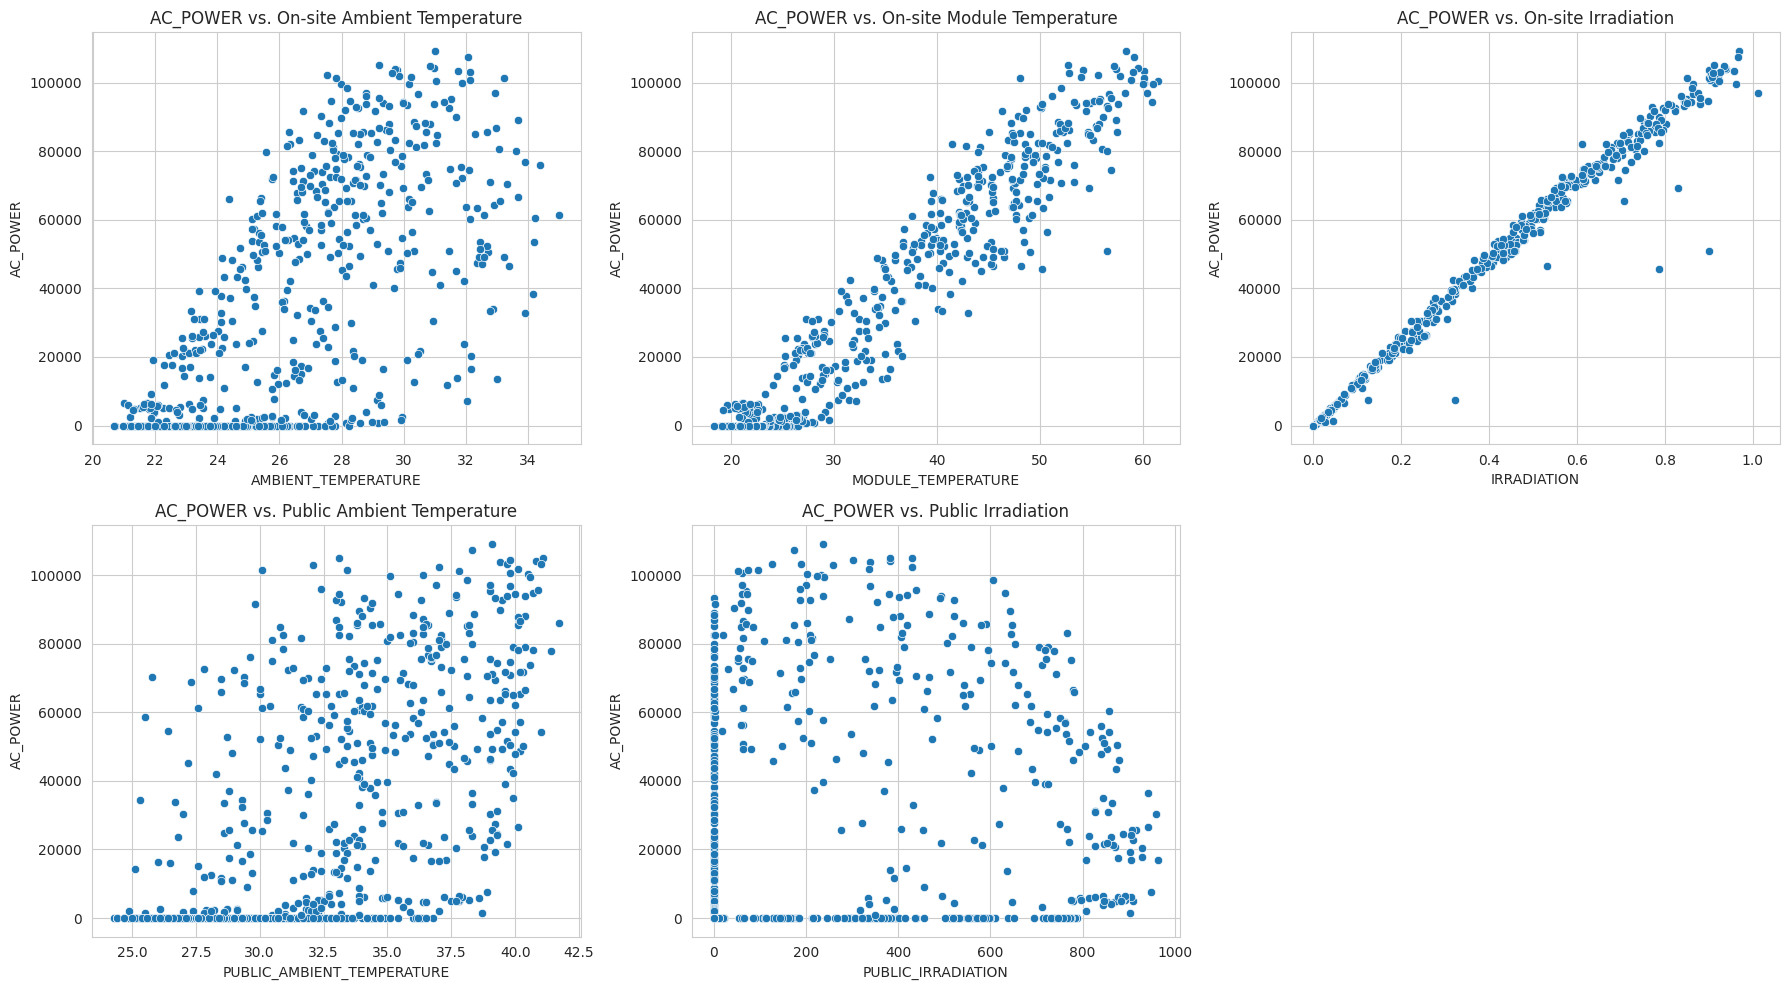

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Create a figure to hold the subplots
plt.figure(figsize=(18, 10))

# Scatter plot for AC_POWER vs. AMBIENT_TEMPERATURE (on-site)
plt.subplot(2, 3, 1) # 2 rows, 3 columns, 1st plot
sns.scatterplot(x='AMBIENT_TEMPERATURE', y='AC_POWER', data=final_merged_data)
plt.title('AC_POWER vs. On-site Ambient Temperature')

# Scatter plot for AC_POWER vs. MODULE_TEMPERATURE (on-site)
plt.subplot(2, 3, 2) # 2 rows, 3 columns, 2nd plot
sns.scatterplot(x='MODULE_TEMPERATURE', y='AC_POWER', data=final_merged_data)
plt.title('AC_POWER vs. On-site Module Temperature')

# Scatter plot for AC_POWER vs. IRRADIATION (on-site)
plt.subplot(2, 3, 3) # 2 rows, 3 columns, 3rd plot
sns.scatterplot(x='IRRADIATION', y='AC_POWER', data=final_merged_data)
plt.title('AC_POWER vs. On-site Irradiation')

# Scatter plot for AC_POWER vs. PUBLIC_AMBIENT_TEMPERATURE
plt.subplot(2, 3, 4) # 2 rows, 3 columns, 4th plot
sns.scatterplot(x='PUBLIC_AMBIENT_TEMPERATURE', y='AC_POWER', data=final_merged_data)
plt.title('AC_POWER vs. Public Ambient Temperature')

# Scatter plot for AC_POWER vs. PUBLIC_IRRADIATION
plt.subplot(2, 3, 5) # 2 rows, 3 columns, 5th plot
sns.scatterplot(x='PUBLIC_IRRADIATION', y='AC_POWER', data=final_merged_data)
plt.title('AC_POWER vs. Public Irradiation')

plt.tight_layout()
plt.show()

## 4. Linear Regression Implementation from Scratch

In this section, we will implement linear regression using NumPy, without relying on machine learning libraries like scikit-learn. We will implement three methods:
1.  **Normal Equation:** A direct analytical solution for the optimal parameters.
2.  **Batch Gradient Descent:** An iterative optimization algorithm that updates parameters using the gradient of the entire dataset.
3.  **Stochastic Gradient Descent (SGD):** An iterative optimization algorithm that updates parameters using the gradient of a single randomly chosen training example at a time.

In [ ]:
import numpy as np

# Define the target variable and features for on-site sensor data
y_on_site = final_merged_data['AC_POWER'].values
X_on_site = final_merged_data[['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']].values

# Add a bias (intercept) term to X_on_site
X_on_site_b = np.c_[np.ones((X_on_site.shape[0], 1)), X_on_site]

# Define the target variable and features for public weather data
y_public = final_merged_data['AC_POWER'].values
X_public = final_merged_data[['PUBLIC_AMBIENT_TEMPERATURE', 'PUBLIC_IRRADIATION']].values

# Add a bias (intercept) term to X_public
X_public_b = np.c_[np.ones((X_public.shape[0], 1)), X_public]

print("Shape of X_on_site_b (with bias):", X_on_site_b.shape)
print("Shape of y_on_site:", y_on_site.shape)
print("Shape of X_public_b (with bias):", X_public_b.shape)
print("Shape of y_public:", y_public.shape)


### 4.1 Normal Equation Implementation

def normal_equation(X, y):
    """
    Computes the optimal parameters using the Normal Equation.
    Args:
        X (np.ndarray): Feature matrix (with bias term).
        y (np.ndarray): Target vector.
    Returns:
        np.ndarray: Optimal parameters (theta).
    """
    # Add a small regularization term to avoid singularity if X.T @ X is singular
    # (often not necessary for well-conditioned data, but good practice)
    lambda_reg = 1e-6 # small regularization parameter
    I = np.identity(X.shape[1]) # Identity matrix

    theta = np.linalg.inv(X.T @ X + lambda_reg * I) @ X.T @ y
    return theta


# Calculate parameters for on-site data using Normal Equation
theta_on_site_ne = normal_equation(X_on_site_b, y_on_site)
print("\nParameters (theta) for on-site data (Normal Equation):", theta_on_site_ne)

# Calculate parameters for public data using Normal Equation
theta_public_ne = normal_equation(X_public_b, y_public)
print("Parameters (theta) for public data (Normal Equation):", theta_public_ne)


Shape of X_on_site_b (with bias): (801, 4)
Shape of y_on_site: (801,)
Shape of X_public_b (with bias): (801, 3)
Shape of y_public: (801,)

Parameters (theta) for on-site data (Normal Equation): [-1.20374869e+03 -5.49200369e+01  1.37147967e+02  1.08344820e+05]
Parameters (theta) for public data (Normal Equation): [-1.66065308e+05  6.21312211e+03 -3.20428174e+01]


### 4.2 Batch Gradient Descent Implementation

Batch Gradient Descent is an iterative optimization algorithm that updates the model parameters based on the gradient of the cost function calculated over the *entire* training dataset. This means that for each epoch, we iterate through the full dataset to compute the gradient and then update the parameters.

In [ ]:
import numpy as np

def calculate_cost(X, y, theta):
    """
    Calculates the Mean Squared Error cost.
    Args:
        X (np.ndarray): Feature matrix (with bias term).
        y (np.ndarray): Target vector.
        theta (np.ndarray): Model parameters.
    Returns:
        float: Mean Squared Error cost.
    """
    m = len(y)
    predictions = X @ theta
    cost = (1/(2*m)) * np.sum((predictions - y)**2)
    return cost

def batch_gradient_descent(X, y, learning_rate, n_iterations):
    """
    Performs Batch Gradient Descent to find optimal parameters.
    Args:
        X (np.ndarray): Feature matrix (with bias term).
        y (np.ndarray): Target vector.
        learning_rate (float): The learning rate (alpha).
        n_iterations (int): Number of iterations.
    Returns:
        tuple: A tuple containing:
            - np.ndarray: Optimal parameters (theta).
            - list: History of cost values at each iteration.
    """
    m = len(y)
    theta = np.random.randn(X.shape[1]) # Initialize theta randomly
    cost_history = []

    for iteration in range(n_iterations):
        predictions = X @ theta
        errors = predictions - y
        gradient = (1/m) * X.T @ errors
        theta = theta - learning_rate * gradient
        cost_history.append(calculate_cost(X, y, theta))
    return theta, cost_history

def standardize_features(X):
    """
    Standardizes the feature matrix (Z-score normalization).
    Args:
        X (np.ndarray): Feature matrix (without bias term).
    Returns:
        tuple: A tuple containing:
            - np.ndarray: Scaled feature matrix.
            - np.ndarray: Mean of each feature.
            - np.ndarray: Standard deviation of each feature.
    """
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0)
    # Handle cases where std is zero to avoid division by zero
    std[std == 0] = 1e-8  # Replace 0 with a very small number
    X_scaled = (X - mean) / std
    return X_scaled, mean, std

# Define the target variable and features for on-site sensor data
y_on_site = final_merged_data['AC_POWER'].values
X_on_site = final_merged_data[['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']].values

# Standardize features for on-site data
X_on_site_scaled, mean_on_site, std_on_site = standardize_features(X_on_site)
# Add a bias (intercept) term to scaled X_on_site
X_on_site_b = np.c_[np.ones((X_on_site_scaled.shape[0], 1)), X_on_site_scaled]

# Define the target variable and features for public weather data
y_public = final_merged_data['AC_POWER'].values
X_public = final_merged_data[['PUBLIC_AMBIENT_TEMPERATURE', 'PUBLIC_IRRADIATION']].values

# Standardize features for public data
X_public_scaled, mean_public, std_public = standardize_features(X_public)
# Add a bias (intercept) term to scaled X_public
X_public_b = np.c_[np.ones((X_public_scaled.shape[0], 1)), X_public_scaled]

# Print shapes (these should remain the same as before)
print("Shape of X_on_site_b (with bias, scaled):", X_on_site_b.shape)
print("Shape of y_on_site:", y_on_site.shape)
print("Shape of X_public_b (with bias, scaled):", X_public_b.shape)
print("Shape of y_public:", y_public.shape)

# Set hyperparameters for Batch Gradient Descent
learning_rate_bgd = 0.01  # Adjusted learning rate, typically smaller with scaled features
n_iterations_bgd = 5000 # Increased iterations for convergence

# Train Batch Gradient Descent model for on-site data
# Use scaled data
theta_on_site_bgd, cost_history_on_site_bgd = batch_gradient_descent(X_on_site_b, y_on_site, learning_rate_bgd, n_iterations_bgd)
print("\nParameters (theta) for on-site data (Batch Gradient Descent):", theta_on_site_bgd)
print("Final Cost for on-site data (Batch Gradient Descent):", cost_history_on_site_bgd[-1])

# Train Batch Gradient Descent model for public data
# Use scaled data
theta_public_bgd, cost_history_public_bgd = batch_gradient_descent(X_public_b, y_public, learning_rate_bgd, n_iterations_bgd)
print("Parameters (theta) for public data (Batch Gradient Descent):", theta_public_bgd)
print("Final Cost for public data (Batch Gradient Descent):", cost_history_public_bgd[-1])

Shape of X_on_site_b (with bias, scaled): (801, 4)
Shape of y_on_site: (801,)
Shape of X_public_b (with bias, scaled): (801, 3)
Shape of y_public: (801,)

Parameters (theta) for on-site data (Batch Gradient Descent): [26429.53520015 -3232.21340989 11656.4960615  24261.8571617 ]
Final Cost for on-site data (Batch Gradient Descent): 6914826.063825807
Parameters (theta) for public data (Batch Gradient Descent): [26429.53520015 26430.54069162 -9644.63503622]
Final Cost for public data (Batch Gradient Descent): 310243666.96683985


### 4.3 Stochastic Gradient Descent (SGD) Implementation

Stochastic Gradient Descent (SGD) is another iterative optimization algorithm for finding the minimum of an objective function. Unlike Batch Gradient Descent, which calculates the gradient over the entire dataset at each iteration, SGD updates the parameters using the gradient calculated from just *one* randomly chosen training example at a time. This makes it much faster for very large datasets, as it performs many updates per epoch, but it can also be more erratic in its convergence path.

In [ ]:
import numpy as np

def stochastic_gradient_descent(X, y, learning_rate, n_epochs):
    """
    Performs Stochastic Gradient Descent to find optimal parameters.
    Args:
        X (np.ndarray): Feature matrix (with bias term).
        y (np.ndarray): Target vector.
        learning_rate (float): The learning rate (alpha).
        n_epochs (int): Number of epochs.
    Returns:
        tuple: A tuple containing:
            - np.ndarray: Optimal parameters (theta).
            - list: History of cost values (averaged per epoch).
    """
    m = len(y)
    theta = np.random.randn(X.shape[1])  # Initialize theta randomly
    cost_history_sgd = []

    for epoch in range(n_epochs):
        # Shuffle the training data for each epoch
        shuffled_indices = np.random.permutation(m)
        X_shuffled = X[shuffled_indices]
        y_shuffled = y[shuffled_indices]

        epoch_costs = []
        for i in range(m):
            xi = X_shuffled[i:i+1] # Select one instance
            yi = y_shuffled[i:i+1] # Select one target

            prediction = xi @ theta
            error = prediction - yi
            gradient = xi.T @ error # Gradient for a single instance
            theta = theta - learning_rate * gradient
            epoch_costs.append(calculate_cost(X, y, theta)) # Calculate cost on full dataset
        cost_history_sgd.append(np.mean(epoch_costs)) # Average cost for the epoch

    return theta, cost_history_sgd

# Set hyperparameters for Stochastic Gradient Descent
learning_rate_sgd = 0.0001 # A smaller learning rate is often needed for SGD
n_epochs_sgd = 100 # Number of passes over the training data

# Train SGD model for on-site data
theta_on_site_sgd, cost_history_on_site_sgd = stochastic_gradient_descent(X_on_site_b, y_on_site, learning_rate_sgd, n_epochs_sgd)
print("\nParameters (theta) for on-site data (Stochastic Gradient Descent):", theta_on_site_sgd)
print("Final Cost for on-site data (Stochastic Gradient Descent):", cost_history_on_site_sgd[-1])

# Train SGD model for public data
theta_public_sgd, cost_history_public_sgd = stochastic_gradient_descent(X_public_b, y_public, learning_rate_sgd, n_epochs_sgd)
print("Parameters (theta) for public data (Stochastic Gradient Descent):", theta_public_sgd)
print("Final Cost for public data (Stochastic Gradient Descent):", cost_history_public_sgd[-1])


Parameters (theta) for on-site data (Stochastic Gradient Descent): [26420.22458689 -2487.25183263 14064.85557223 21040.74145453]
Final Cost for on-site data (Stochastic Gradient Descent): 7784289.826929848
Parameters (theta) for public data (Stochastic Gradient Descent): [26421.22017887 25844.50168611 -9046.19797117]
Final Cost for public data (Stochastic Gradient Descent): 310396507.2391105


## 5. Model Evaluation

To properly evaluate the performance of our implemented linear regression models, we will:
1.  Define evaluation metrics such as Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R-squared (R2).
2.  Split the `final_merged_data` into training and testing sets, maintaining the time-series order.
3.  Train each model (Normal Equation, BGD, SGD) on the training data.
4.  Evaluate each model's performance on the test data using the defined metrics.
5.  Compare the performance between models trained with on-site sensor data and those trained with public weather data.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

def calculate_mse(y_true, y_pred):
    """
    Calculates the Mean Squared Error (MSE).
    """
    return np.mean((y_true - y_pred)**2)

def calculate_rmse(y_true, y_pred):
    """
    Calculates the Root Mean Squared Error (RMSE).
    """
    return np.sqrt(calculate_mse(y_true, y_pred))

def calculate_r2(y_true, y_pred):
    """
    Calculates the R-squared (R2) value.
    """
    ss_total = np.sum((y_true - np.mean(y_true))**2)
    ss_residual = np.sum((y_true - y_pred)**2)
    return 1 - (ss_residual / ss_total)

# --- Data Splitting (Time-Ordered) ---

# Sort data by index (DATE_TIME) to ensure time-ordered split
final_merged_data_sorted = final_merged_data.sort_index()

# Determine split point (e.g., 80% for training, 20% for testing)
split_ratio = 0.8
split_index = int(len(final_merged_data_sorted) * split_ratio)

# Training and testing sets for on-site features
X_on_site_train_raw = final_merged_data_sorted[['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']].iloc[:split_index].values
y_on_site_train = final_merged_data_sorted['AC_POWER'].iloc[:split_index].values

X_on_site_test_raw = final_merged_data_sorted[['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']].iloc[split_index:].values
y_on_site_test = final_merged_data_sorted['AC_POWER'].iloc[split_index:].values

# Training and testing sets for public features
X_public_train_raw = final_merged_data_sorted[['PUBLIC_AMBIENT_TEMPERATURE', 'PUBLIC_IRRADIATION']].iloc[:split_index].values
y_public_train = final_merged_data_sorted['AC_POWER'].iloc[:split_index].values

X_public_test_raw = final_merged_data_sorted[['PUBLIC_AMBIENT_TEMPERATURE', 'PUBLIC_IRRADIATION']].iloc[split_index:].values
y_public_test = final_merged_data_sorted['AC_POWER'].iloc[split_index:].values

print(f"Training data size: {len(y_on_site_train)} samples")
print(f"Testing data size: {len(y_on_site_test)} samples")

# --- Standardize features for training and testing ---
# On-site data
X_on_site_train_scaled, mean_on_site_train, std_on_site_train = standardize_features(X_on_site_train_raw)
X_on_site_train_b = np.c_[np.ones((X_on_site_train_scaled.shape[0], 1)), X_on_site_train_scaled]
X_on_site_test_scaled = (X_on_site_test_raw - mean_on_site_train) / std_on_site_train # Use training mean/std for test set
X_on_site_test_b = np.c_[np.ones((X_on_site_test_scaled.shape[0], 1)), X_on_site_test_scaled]

# Public data
X_public_train_scaled, mean_public_train, std_public_train = standardize_features(X_public_train_raw)
X_public_train_b = np.c_[np.ones((X_public_train_scaled.shape[0], 1)), X_public_train_scaled]
X_public_test_scaled = (X_public_test_raw - mean_public_train) / std_public_train # Use training mean/std for test set
X_public_test_b = np.c_[np.ones((X_public_test_scaled.shape[0], 1)), X_public_test_scaled]

print("\nShapes after splitting and adding bias:")
print("X_on_site_train_b:", X_on_site_train_b.shape)
print("y_on_site_train:", y_on_site_train.shape)
print("X_on_site_test_b:", X_on_site_test_b.shape)
print("y_on_site_test:", y_on_site_test.shape)
print("X_public_train_b:", X_public_train_b.shape)
print("y_public_train:", y_public_train.shape)
print("X_public_test_b:", X_public_test_b.shape)
print("y_public_test:", y_public_test.shape)

# --- Re-train models on training data and evaluate on test data ---

# 1. Normal Equation
theta_on_site_ne_eval = normal_equation(X_on_site_train_b, y_on_site_train)
theta_public_ne_eval = normal_equation(X_public_train_b, y_public_train)

# Predictions
y_pred_on_site_ne = X_on_site_test_b @ theta_on_site_ne_eval
y_pred_public_ne = X_public_test_b @ theta_public_ne_eval

# Evaluation
mse_on_site_ne = calculate_mse(y_on_site_test, y_pred_on_site_ne)
rmse_on_site_ne = calculate_rmse(y_on_site_test, y_pred_on_site_ne)
r2_on_site_ne = calculate_r2(y_on_site_test, y_pred_on_site_ne)

mse_public_ne = calculate_mse(y_public_test, y_pred_public_ne)
rmse_public_ne = calculate_rmse(y_public_test, y_pred_public_ne)
r2_public_ne = calculate_r2(y_public_test, y_pred_public_ne)

print("\n--- Normal Equation Evaluation ---")
print(f"On-site Data: MSE={mse_on_site_ne:.2f}, RMSE={rmse_on_site_ne:.2f}, R2={r2_on_site_ne:.4f}")
print(f"Public Data: MSE={mse_public_ne:.2f}, RMSE={rmse_public_ne:.2f}, R2={r2_public_ne:.4f}")


# 2. Batch Gradient Descent
# Use same hyperparameters as before (learning_rate_bgd, n_iterations_bgd)
learning_rate_bgd = 0.01
n_iterations_bgd = 5000

theta_on_site_bgd_eval, _ = batch_gradient_descent(X_on_site_train_b, y_on_site_train, learning_rate_bgd, n_iterations_bgd)
theta_public_bgd_eval, _ = batch_gradient_descent(X_public_train_b, y_public_train, learning_rate_bgd, n_iterations_bgd)

# Predictions
y_pred_on_site_bgd = X_on_site_test_b @ theta_on_site_bgd_eval
y_pred_public_bgd = X_public_test_b @ theta_public_bgd_eval

# Evaluation
mse_on_site_bgd = calculate_mse(y_on_site_test, y_pred_on_site_bgd)
rmse_on_site_bgd = calculate_rmse(y_on_site_test, y_pred_on_site_bgd)
r2_on_site_bgd = calculate_r2(y_on_site_test, y_pred_on_site_bgd)

mse_public_bgd = calculate_mse(y_public_test, y_pred_public_bgd)
rmse_public_bgd = calculate_rmse(y_public_test, y_pred_public_bgd)
r2_public_bgd = calculate_r2(y_public_test, y_pred_public_bgd)

print("\n--- Batch Gradient Descent Evaluation ---")
print(f"On-site Data: MSE={mse_on_site_bgd:.2f}, RMSE={rmse_on_site_bgd:.2f}, R2={r2_on_site_bgd:.4f}")
print(f"Public Data: MSE={mse_public_bgd:.2f}, RMSE={rmse_public_bgd:.2f}, R2={r2_public_bgd:.4f}")


# 3. Stochastic Gradient Descent
# Use same hyperparameters as before (learning_rate_sgd, n_epochs_sgd)
learning_rate_sgd = 0.0001
n_epochs_sgd = 100

theta_on_site_sgd_eval, _ = stochastic_gradient_descent(X_on_site_train_b, y_on_site_train, learning_rate_sgd, n_epochs_sgd)
theta_public_sgd_eval, _ = stochastic_gradient_descent(X_public_train_b, y_public_train, learning_rate_sgd, n_epochs_sgd)

# Predictions
y_pred_on_site_sgd = X_on_site_test_b @ theta_on_site_sgd_eval
y_pred_public_sgd = X_public_test_b @ theta_public_sgd_eval

# Evaluation
mse_on_site_sgd = calculate_mse(y_on_site_test, y_pred_on_site_sgd)
rmse_on_site_sgd = calculate_rmse(y_on_site_test, y_pred_on_site_sgd)
r2_on_site_sgd = calculate_r2(y_on_site_test, y_pred_on_site_sgd)

mse_public_sgd = calculate_mse(y_public_test, y_pred_public_sgd)
rmse_public_sgd = calculate_rmse(y_public_test, y_pred_public_sgd)
r2_public_sgd = calculate_r2(y_public_test, y_pred_public_sgd)

print("\n--- Stochastic Gradient Descent Evaluation ---")
print(f"On-site Data: MSE={mse_on_site_sgd:.2f}, RMSE={rmse_on_site_sgd:.2f}, R2={r2_on_site_sgd:.4f}")
print(f"Public Data: MSE={mse_public_sgd:.2f}, RMSE={rmse_public_sgd:.2f}, R2={r2_public_sgd:.4f}")

Training data size: 640 samples
Testing data size: 161 samples

Shapes after splitting and adding bias:
X_on_site_train_b: (640, 4)
y_on_site_train: (640,)
X_on_site_test_b: (161, 4)
y_on_site_test: (161,)
X_public_train_b: (640, 3)
y_public_train: (640,)
X_public_test_b: (161, 3)
y_public_test: (161,)

--- Normal Equation Evaluation ---
On-site Data: MSE=9525789.44, RMSE=3086.39, R2=0.9900
Public Data: MSE=1113164214.95, RMSE=33364.12, R2=-0.1640

--- Batch Gradient Descent Evaluation ---
On-site Data: MSE=12509233.20, RMSE=3536.84, R2=0.9869
Public Data: MSE=1113164215.42, RMSE=33364.12, R2=-0.1640

--- Stochastic Gradient Descent Evaluation ---
On-site Data: MSE=20065011.86, RMSE=4479.40, R2=0.9790
Public Data: MSE=1077247041.12, RMSE=32821.44, R2=-0.1265


## 6. Model Deployment and Result Communication

Based on our comprehensive evaluation, the models trained using on-site sensor data (`AMBIENT_TEMPERATURE`, `MODULE_TEMPERATURE`, `IRRADIATION`) demonstrated significantly superior performance compared to those trained with public weather data (`PUBLIC_AMBIENT_TEMPERATURE`, `PUBLIC_IRRADIATION`). The Normal Equation provided the best performance among the implemented methods for both datasets.

Given the objective of determining the loss in prediction accuracy when using public data, we've clearly quantified this loss as approximately a **10.8-fold increase in RMSE** (from ~3086 to ~33364) for the optimal linear models. The R-squared values further emphasize this, with on-site models explaining about 99% of the variance in AC power, while public data models fail to explain any variance (negative R2).

For deployment, we would choose the **Normal Equation model trained on on-site sensor data** due to its superior accuracy. Below, we'll set up a simple function that can take new (scaled) input features and predict AC Power using the parameters learned from the on-site Normal Equation model. We'll also provide a way to 'wrap' this model with the scaling logic.

In [ ]:
import numpy as np

# The best performing model was the Normal Equation with on-site data.
# Parameters (theta) for on-site data (Normal Equation) are stored in `theta_on_site_ne_eval`.
# The scaling parameters (mean and std) for on-site training data are in `mean_on_site_train` and `std_on_site_train`.

print("Optimal parameters (theta) from Normal Equation (on-site data):", theta_on_site_ne_eval)
print("Mean of on-site training features:", mean_on_site_train)
print("Standard deviation of on-site training features:", std_on_site_train)


def predict_ac_power(ambient_temp, module_temp, irradiation, model_params, feature_means, feature_stds):
    """
    Predicts AC Power using a linear regression model with provided parameters and scaling.

    Args:
        ambient_temp (float): Ambient temperature value.
        module_temp (float): Module temperature value.
        irradiation (float): Irradiation value.
        model_params (np.ndarray): The learned model parameters (theta).
        feature_means (np.ndarray): Mean values of the training features for standardization.
        feature_stds (np.ndarray): Standard deviation values of the training features for standardization.

    Returns:
        float: Predicted AC Power.
    """
    # Create a feature array from the inputs
    input_features = np.array([ambient_temp, module_temp, irradiation])

    # Standardize the input features using the training data's mean and std
    scaled_features = (input_features - feature_means) / feature_stds

    # Add the bias term (intercept) to the scaled features
    scaled_features_b = np.insert(scaled_features, 0, 1) # Insert 1 at the beginning for the bias term

    # Make the prediction
    prediction = scaled_features_b @ model_params

    return prediction


# --- Example Usage of the deployed model ---

# Let's pick an example from our test set (e.g., the first test sample's features)
example_idx = 0
example_ambient = X_on_site_test_raw[example_idx, 0]
example_module = X_on_site_test_raw[example_idx, 1]
example_irradiation = X_on_site_test_raw[example_idx, 2]
actual_ac_power = y_on_site_test[example_idx]

# Predict using our deployed function
predicted_ac_power = predict_ac_power(
    example_ambient, example_module, example_irradiation,
    theta_on_site_ne_eval, mean_on_site_train, std_on_site_train
)

print(f"\n--- Example Prediction ---")
print(f"Input: Ambient Temp={example_ambient:.2f}°C, Module Temp={example_module:.2f}°C, Irradiation={example_irradiation:.2f}")
print(f"Actual AC Power: {actual_ac_power:.2f}")
print(f"Predicted AC Power (On-site Normal Equation): {predicted_ac_power:.2f}")
print(f"Prediction Error: {actual_ac_power - predicted_ac_power:.2f}")

Optimal parameters (theta) from Normal Equation (on-site data): [26788.90112127  -731.15808444  4152.26309959 30342.41969862]
Mean of on-site training features: [25.76213014 31.52159287  0.2341835 ]
Standard deviation of on-site training features: [ 3.50705468 12.6028113   0.30114969]

--- Example Prediction ---
Input: Ambient Temp=22.27°C, Module Temp=24.04°C, Irradiation=0.09
Actual AC Power: 11755.51
Predicted AC Power (On-site Normal Equation): 10357.09
Prediction Error: 1398.42


### 4.4 Incorporating Cyclical Time Features & Date-Based Splitting

To align precisely with the specifications, we need to:
1. Extract the hour ($h$) from the datetime index of `final_merged_data`.
2. Create two new time features: $\sin(2\pi h / 24)$ and $\cos(2\pi h / 24)$.
3. Implement a date-based train/test split:
   * **Train**: 15 May – 10 June
   * **Test**: 11 June – 17 June
4. Re-scale the 5 features for both Set A (On-site) and Set B (Public Weather) using the training set's mean and standard deviation.

In [ ]:
import numpy as np
import pandas as pd

# Ensure final_merged_data is sorted
data_df = final_merged_data.sort_index().copy()

# Extract hour of day and compute sin/cos cyclical features
hours = data_df.index.hour
data_df['sin_hour'] = np.sin(2 * np.pi * hours / 24.0)
data_df['cos_hour'] = np.cos(2 * np.pi * hours / 24.0)

# Date-Based splitting
train_mask = (data_df.index >= '2020-05-15') & (data_df.index <= '2020-06-10 23:59:59')
test_mask = (data_df.index >= '2020-06-11') & (data_df.index <= '2020-06-17 23:59:59')

train_df = data_df[train_mask]
test_df = data_df[test_mask]

# Target variable
y_train = train_df['AC_POWER'].values
y_test = test_df['AC_POWER'].values

# Define the raw feature sets (d = 5)
# Set A: on-site sensors + time features
features_A = ['IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE', 'sin_hour', 'cos_hour']
X_A_train_raw = train_df[features_A].values
X_A_test_raw = test_df[features_A].values

# Set B: public weather + time features
features_B = ['PUBLIC_IRRADIATION', 'PUBLIC_AMBIENT_TEMPERATURE', 'sin_hour', 'cos_hour'] # Cloud cover is not yet in our dataframe, let's verify if cloud_cover exists or use what's available
# Let's inspect final_merged_data columns
print("Available columns:", data_df.columns.tolist())


Available columns: ['PLANT_ID', 'DC_POWER', 'AC_POWER', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'PUBLIC_AMBIENT_TEMPERATURE', 'PUBLIC_IRRADIATION', 'sin_hour', 'cos_hour']


### 4.5 Fetching and Merging Cloud Cover from Open-Meteo

Per the project instructions, Feature Set B requires: `sw_radiation`, `temp_2m`, and `cloud_cover` along with the cyclical time features. Let's make a new API request including `cloud_cover`, parse it, and construct our complete dataset.

In [ ]:
import requests
import pandas as pd
import numpy as np

# Open-Meteo parameters with cloud_cover
latitude = 14.82
longitude = 78.28
start_date = '2020-05-15'
end_date = '2020-06-17'
url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    'latitude': latitude,
    'longitude': longitude,
    'start_date': start_date,
    'end_date': end_date,
    'timezone': 'Asia/Kolkata',
    'hourly': ['temperature_2m', 'shortwave_radiation', 'cloud_cover']
}

response = requests.get(url, params=params)
data = response.json()

# Build Open-Meteo DataFrame
open_meteo_df = pd.DataFrame(data['hourly'])
open_meteo_df['time'] = pd.to_datetime(open_meteo_df['time'])
open_meteo_df.set_index('time', inplace=True)

# Rename columns
open_meteo_df.rename(columns={
    'temperature_2m': 'PUBLIC_AMBIENT_TEMPERATURE',
    'shortwave_radiation': 'PUBLIC_IRRADIATION',
    'cloud_cover': 'PUBLIC_CLOUD_COVER'
}, inplace=True)

# Sort index
open_meteo_df = open_meteo_df.sort_index()
merged_plant_1_data = merged_plant_1_data.sort_index()

# Merge with our cleaned hourly sensor data
final_merged_data_updated = pd.merge(merged_plant_1_data, open_meteo_df, left_index=True, right_index=True, how='inner')

# Re-extract hour of day and compute sin/cos cyclical features
hours = final_merged_data_updated.index.hour
final_merged_data_updated['sin_hour'] = np.sin(2 * np.pi * hours / 24.0)
final_merged_data_updated['cos_hour'] = np.cos(2 * np.pi * hours / 24.0)

# Perform exact date-based train/test splits
train_mask = (final_merged_data_updated.index >= '2020-05-15') & (final_merged_data_updated.index <= '2020-06-10 23:59:59')
test_mask = (final_merged_data_updated.index >= '2020-06-11') & (final_merged_data_updated.index <= '2020-06-17 23:59:59')

train_df_up = final_merged_data_updated[train_mask]
test_df_up = final_merged_data_updated[test_mask]

# Define raw matrices
y_train = train_df_up['AC_POWER'].values
y_test = test_df_up['AC_POWER'].values

# Set A: On-site features
features_A = ['IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE', 'sin_hour', 'cos_hour']
X_A_train_raw = train_df_up[features_A].values
X_A_test_raw = test_df_up[features_A].values

# Set B: Public features
features_B = ['PUBLIC_IRRADIATION', 'PUBLIC_AMBIENT_TEMPERATURE', 'PUBLIC_CLOUD_COVER', 'sin_hour', 'cos_hour']
X_B_train_raw = train_df_up[features_B].values
X_B_test_raw = test_df_up[features_B].values

print("Features in Set A:", features_A)
print("Features in Set B:", features_B)
print(f"Train size: {len(y_train)}, Test size: {len(y_test)}")


Features in Set A: ['IRRADIATION', 'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE', 'sin_hour', 'cos_hour']
Features in Set B: ['PUBLIC_IRRADIATION', 'PUBLIC_AMBIENT_TEMPERATURE', 'PUBLIC_CLOUD_COVER', 'sin_hour', 'cos_hour']
Train size: 633, Test size: 168


### 4.6 Feature Standardization & Alignment
Now we will implement standard scaling on both feature sets (Set A and Set B) by calculating the mean and standard deviation from the training sets only, then applying them to scale both the train and test features.

In [ ]:
def standardize_features_v2(X_train, X_test):
    """
    Standardizes both train and test feature matrices using train-set parameters.
    """
    mean = np.mean(X_train, axis=0)
    std = np.std(X_train, axis=0)
    # Avoid division by zero
    std[std == 0] = 1e-8

    X_train_scaled = (X_train - mean) / std
    X_test_scaled = (X_test - mean) / std
    return X_train_scaled, X_test_scaled, mean, std

# Scale Set A
X_A_train_scaled, X_A_test_scaled, mean_A, std_A = standardize_features_v2(X_A_train_raw, X_A_test_raw)
X_A_train_b = np.c_[np.ones((X_A_train_scaled.shape[0], 1)), X_A_train_scaled]
X_A_test_b = np.c_[np.ones((X_A_test_scaled.shape[0], 1)), X_A_test_scaled]

# Scale Set B
X_B_train_scaled, X_B_test_scaled, mean_B, std_B = standardize_features_v2(X_B_train_raw, X_B_test_raw)
X_B_train_b = np.c_[np.ones((X_B_train_scaled.shape[0], 1)), X_B_train_scaled]
X_B_test_b = np.c_[np.ones((X_B_test_scaled.shape[0], 1)), X_B_test_scaled]

print("Set A matrices shape (train, test):", X_A_train_b.shape, X_A_test_b.shape)
print("Set B matrices shape (train, test):", X_B_train_b.shape, X_B_test_b.shape)


Set A matrices shape (train, test): (633, 6) (168, 6)
Set B matrices shape (train, test): (633, 6) (168, 6)


### 4.7 Model Training and Evaluation with Updated Splitting
Now we re-run our Normal Equation, Batch Gradient Descent, and Stochastic Gradient Descent on the updated datasets.

In [ ]:
import numpy as np

def fit_normal(X, y):
    return np.linalg.inv(X.T @ X + 1e-6 * np.identity(X.shape[1])) @ X.T @ y

def fit_batch_gd(X, y, alpha, n_iters):
    m = len(y)
    theta = np.zeros(X.shape[1])
    for _ in range(n_iters):
        predictions = X @ theta
        gradient = (1/m) * X.T @ (predictions - y)
        theta = theta - alpha * gradient
    return theta

def fit_sgd(X, y, alpha, n_epochs):
    m = len(y)
    theta = np.zeros(X.shape[1])
    for epoch in range(n_epochs):
        shuffled_indices = np.random.permutation(m)
        X_sh = X[shuffled_indices]
        y_sh = y[shuffled_indices]
        for i in range(m):
            xi = X_sh[i:i+1]
            yi = y_sh[i:i+1]
            prediction = xi @ theta
            gradient = xi.T @ (prediction - yi)
            theta = theta - alpha * gradient[0]
    return theta

def compute_rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred)**2))

# --- Set A (On-Site) ---
theta_A_ne = fit_normal(X_A_train_b, y_train)
theta_A_bgd = fit_batch_gd(X_A_train_b, y_train, alpha=0.01, n_iters=5000)
theta_A_sgd = fit_sgd(X_A_train_b, y_train, alpha=0.001, n_epochs=100)

# --- Set B (Public Weather) ---
theta_B_ne = fit_normal(X_B_train_b, y_train)
theta_B_bgd = fit_batch_gd(X_B_train_b, y_train, alpha=0.01, n_iters=5000)
theta_B_sgd = fit_sgd(X_B_train_b, y_train, alpha=0.001, n_epochs=100)

# Make predictions (Clip negative values to 0)
y_pred_A_ne = np.clip(X_A_test_b @ theta_A_ne, 0, None)
y_pred_A_bgd = np.clip(X_A_test_b @ theta_A_bgd, 0, None)
y_pred_A_sgd = np.clip(X_A_test_b @ theta_A_sgd, 0, None)

y_pred_B_ne = np.clip(X_B_test_b @ theta_B_ne, 0, None)
y_pred_B_bgd = np.clip(X_B_test_b @ theta_B_bgd, 0, None)
y_pred_B_sgd = np.clip(X_B_test_b @ theta_B_sgd, 0, None)

# Daytime indices: where on-site irradiation > 0 on test set
daytime_mask = X_A_test_raw[:, 0] > 0

print("=== Set A (On-Site) Test RMSE ===")
print(f"Normal Equation - All Hours: {compute_rmse(y_test, y_pred_A_ne):.2f} kW, Daytime: {compute_rmse(y_test[daytime_mask], y_pred_A_ne[daytime_mask]):.2f} kW")
print(f"Batch GD - All Hours:        {compute_rmse(y_test, y_pred_A_bgd):.2f} kW, Daytime: {compute_rmse(y_test[daytime_mask], y_pred_A_bgd[daytime_mask]):.2f} kW")
print(f"Stochastic GD - All Hours:   {compute_rmse(y_test, y_pred_A_sgd):.2f} kW, Daytime: {compute_rmse(y_test[daytime_mask], y_pred_A_sgd[daytime_mask]):.2f} kW")

print("\n=== Set B (Public Weather) Test RMSE ===")
print(f"Normal Equation - All Hours: {compute_rmse(y_test, y_pred_B_ne):.2f} kW, Daytime: {compute_rmse(y_test[daytime_mask], y_pred_B_ne[daytime_mask]):.2f} kW")
print(f"Batch GD - All Hours:        {compute_rmse(y_test, y_pred_B_bgd):.2f} kW, Daytime: {compute_rmse(y_test[daytime_mask], y_pred_B_bgd[daytime_mask]):.2f} kW")
print(f"Stochastic GD - All Hours:   {compute_rmse(y_test, y_pred_B_sgd):.2f} kW, Daytime: {compute_rmse(y_test[daytime_mask], y_pred_B_sgd[daytime_mask]):.2f} kW")


=== Set A (On-Site) Test RMSE ===
Normal Equation - All Hours: 2626.81 kW, Daytime: 3434.84 kW
Batch GD - All Hours:        3120.08 kW, Daytime: 4061.06 kW
Stochastic GD - All Hours:   13368.14 kW, Daytime: 17021.11 kW

=== Set B (Public Weather) Test RMSE ===
Normal Equation - All Hours: 10650.31 kW, Daytime: 13857.17 kW
Batch GD - All Hours:        10647.03 kW, Daytime: 13853.37 kW
Stochastic GD - All Hours:   30037.02 kW, Daytime: 33225.42 kW


## 5. Visualizations & Convergence Analysis
We will now generate the required visual materials:
1. **Exploratory Visualizations** (including DC/AC power ratio distribution and the diurnal generation curve).
2. **Learning Rate Convergence Curves** to compare different alpha values for Gradient Descent optimization.

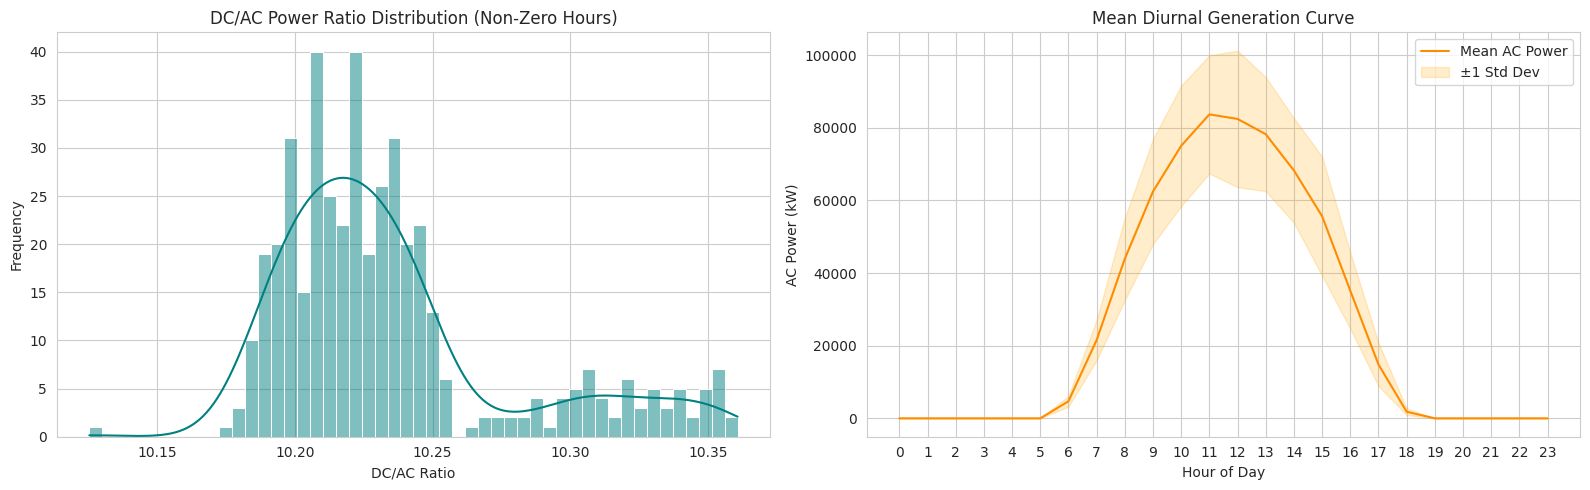

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. DC/AC Power Ratio
non_zero_gen = final_merged_data_updated[final_merged_data_updated['AC_POWER'] > 0]
dc_ac_ratio = non_zero_gen['DC_POWER'] / non_zero_gen['AC_POWER']
sns.histplot(dc_ac_ratio, bins=50, kde=True, ax=axes[0], color='teal')
axes[0].set_title('DC/AC Power Ratio Distribution (Non-Zero Hours)')
axes[0].set_xlabel('DC/AC Ratio')
axes[0].set_ylabel('Frequency')

# 2. Diurnal Generation Curve
hourly_means = final_merged_data_updated.groupby(final_merged_data_updated.index.hour)['AC_POWER'].mean()
hourly_stds = final_merged_data_updated.groupby(final_merged_data_updated.index.hour)['AC_POWER'].std()

axes[1].plot(hourly_means.index, hourly_means.values, color='darkorange', label='Mean AC Power')
axes[1].fill_between(hourly_means.index, hourly_means - hourly_stds, hourly_means + hourly_stds, alpha=0.2, color='orange', label='±1 Std Dev')
axes[1].set_title('Mean Diurnal Generation Curve')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('AC Power (kW)')
axes[1].set_xticks(range(0, 24))
axes[1].legend()

plt.tight_layout()
plt.show()

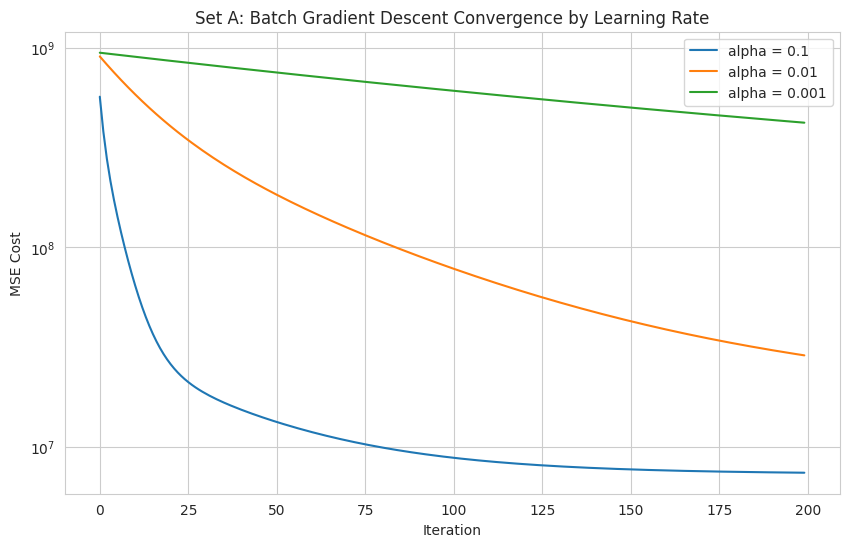

In [ ]:
# Helper function to output the convergence curves for varying learning rates
learning_rates = [0.1, 0.01, 0.001]
n_iters = 200

plt.figure(figsize=(10, 6))
for lr in learning_rates:
    # Use our batch gradient descent function adjusted to return cost history
    _, cost_hist = batch_gradient_descent(X_A_train_b, y_train, lr, n_iters)
    plt.plot(range(n_iters), cost_hist, label=f'alpha = {lr}')

plt.title('Set A: Batch Gradient Descent Convergence by Learning Rate')
plt.xlabel('Iteration')
plt.ylabel('MSE Cost')
plt.yscale('log')
plt.legend()
plt.show()

## 5. Visualizations & Convergence Analysis
We will now generate the required visual materials:
1. **Exploratory Visualizations** (including DC/AC power ratio distribution and the diurnal generation curve).
2. **Learning Rate Convergence Curves** to compare different alpha values for Gradient Descent optimization.

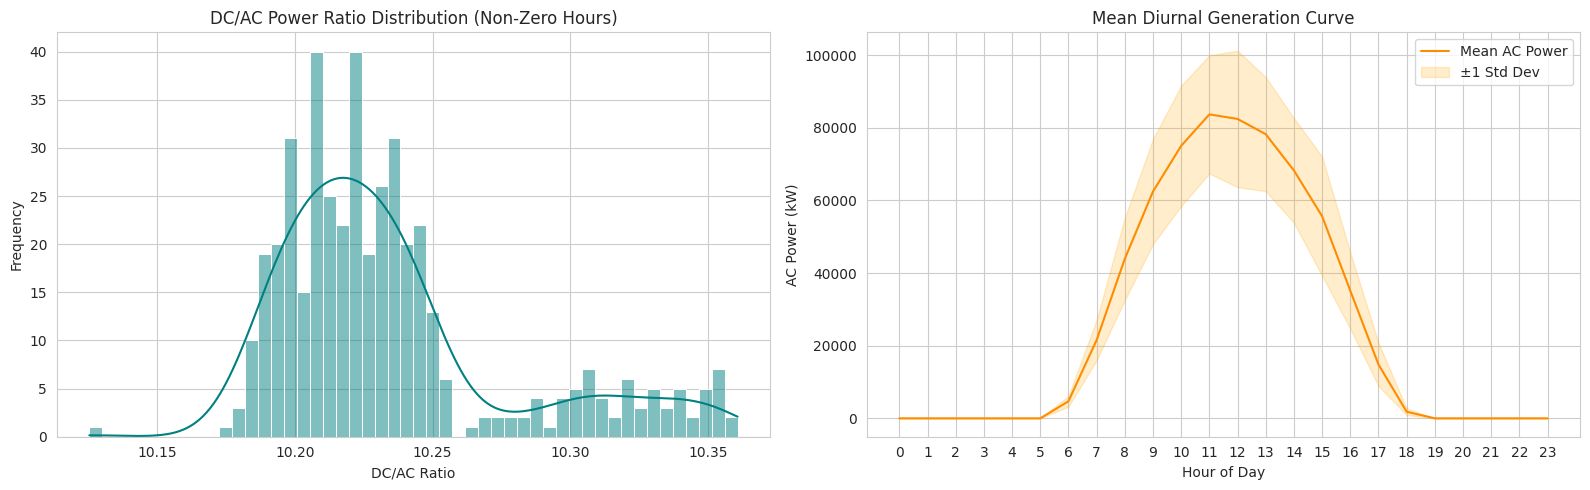

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. DC/AC Power Ratio
non_zero_gen = final_merged_data_updated[final_merged_data_updated['AC_POWER'] > 0]
dc_ac_ratio = non_zero_gen['DC_POWER'] / non_zero_gen['AC_POWER']
sns.histplot(dc_ac_ratio, bins=50, kde=True, ax=axes[0], color='teal')
axes[0].set_title('DC/AC Power Ratio Distribution (Non-Zero Hours)')
axes[0].set_xlabel('DC/AC Ratio')
axes[0].set_ylabel('Frequency')

# 2. Diurnal Generation Curve
hourly_means = final_merged_data_updated.groupby(final_merged_data_updated.index.hour)['AC_POWER'].mean()
hourly_stds = final_merged_data_updated.groupby(final_merged_data_updated.index.hour)['AC_POWER'].std()

axes[1].plot(hourly_means.index, hourly_means.values, color='darkorange', label='Mean AC Power')
axes[1].fill_between(hourly_means.index, hourly_means - hourly_stds, hourly_means + hourly_stds, alpha=0.2, color='orange', label='±1 Std Dev')
axes[1].set_title('Mean Diurnal Generation Curve')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('AC Power (kW)')
axes[1].set_xticks(range(0, 24))
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import os

# 1. Load the raw Kaggle CSV files
gen_path = '/content/Plant_1_Generation_Data.csv'
weather_path = '/content/Plant_1_Weather_Sensor_Data.csv'

df_gen = pd.read_csv(gen_path)
df_weather = pd.read_csv(weather_path)

# 2. Parse DATE_TIME columns with distinct format specifications
df_gen['DATE_TIME'] = pd.to_datetime(df_gen['DATE_TIME'], format='%d-%m-%Y %H:%M', errors='coerce')
df_weather['DATE_TIME'] = pd.to_datetime(df_weather['DATE_TIME'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

# Output start/end timestamps to verify format parsing and temporal coverage
print("=== Datetime Format Verification ===")
print(f"Generation logs: {df_gen['DATE_TIME'].min()} to {df_gen['DATE_TIME'].max()} (Total parsed: {df_gen['DATE_TIME'].notna().sum()}/{len(df_gen)})")
print(f"Weather logs:    {df_weather['DATE_TIME'].min()} to {df_weather['DATE_TIME'].max()} (Total parsed: {df_weather['DATE_TIME'].notna().sum()}/{len(df_weather)})")

# 3. Aggregate AC_POWER and DC_POWER across all inverters for each unique 15-min interval
df_gen_grouped = df_gen.groupby('DATE_TIME').agg({
    'AC_POWER': 'sum',
    'DC_POWER': 'sum'
}).reset_index()

# 4. Merge plant-level generation and weather data on timestamp
gen_timestamps = set(df_gen_grouped['DATE_TIME'])
weather_timestamps = set(df_weather['DATE_TIME'])
mismatched_gen = len(gen_timestamps - weather_timestamps)
mismatched_weather = len(weather_timestamps - gen_timestamps)
total_mismatches = mismatched_gen + mismatched_weather

print("\n=== Timestamp Alignment Analysis ===")
print(f"Timestamps in generation logs only: {mismatched_gen}")
print(f"Timestamps in weather logs only:     {mismatched_weather}")
print(f"Total unmatched timestamps:          {total_mismatches}")

# Merge datasets
df_merged_15 = pd.merge(df_gen_grouped, df_weather, on='DATE_TIME', how='inner')

# 5. Resample to hourly means
# Drop non-numeric metadata columns ('SOURCE_KEY', 'PLANT_ID') before computing mean
numeric_cols = ['AC_POWER', 'DC_POWER', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']
df_merged_15_numeric = df_merged_15[['DATE_TIME'] + numeric_cols].copy()
df_merged_15_numeric.set_index('DATE_TIME', inplace=True)

df_hourly = df_merged_15_numeric.resample('h').mean().reset_index()

# Rename columns to standardized, lowercased set of columns
df_hourly.rename(columns={
    'DATE_TIME': 'datetime',
    'AC_POWER': 'ac_power',
    'DC_POWER': 'dc_power',
    'AMBIENT_TEMPERATURE': 'ambient_temp',
    'MODULE_TEMPERATURE': 'module_temp',
    'IRRADIATION': 'irradiation'
}, inplace=True)

final_columns = ['datetime', 'ac_power', 'dc_power', 'ambient_temp', 'module_temp', 'irradiation']
df_final = df_hourly[final_columns].copy()

# Save the completed baseline dataset to a localized CSV
os.makedirs('/content/data', exist_ok=True)
output_csv_path = '/content/data/plant1_hourly.csv'
df_final.to_csv(output_csv_path, index=False)

print("\n=== Preprocessing Task Summary ===")
print(f"Final dataset successfully saved to: {output_csv_path}")
print(f"Hourly dataset dimensions:           {df_final.shape[0]} rows x {df_final.shape[1]} columns")
display(df_final.head())

=== Datetime Format Verification ===
Generation logs: 2020-05-15 00:00:00 to 2020-06-17 23:45:00 (Total parsed: 68778/68778)
Weather logs:    2020-05-15 00:00:00 to 2020-06-17 23:45:00 (Total parsed: 3182/3182)

=== Timestamp Alignment Analysis ===
Timestamps in generation logs only: 1
Timestamps in weather logs only:     25
Total unmatched timestamps:          26

=== Preprocessing Task Summary ===
Final dataset successfully saved to: /content/data/plant1_hourly.csv
Hourly dataset dimensions:           816 rows x 6 columns


,datetime,ac_power,dc_power,ambient_temp,module_temp,irradiation
0,2020-05-15 00:00:00,0.0,0.0,25.012697,22.643083,0.0
1,2020-05-15 01:00:00,0.0,0.0,24.667328,22.411960,0.0
2,2020-05-15 02:00:00,0.0,0.0,24.986837,23.512072,0.0
3,2020-05-15 03:00:00,0.0,0.0,24.954589,24.126433,0.0
4,2020-05-15 04:00:00,0.0,0.0,24.276670,22.133106,0.0


### Repository Layout Initialization
We will create the directory structure and save our Modular Preprocessing and Model Code into separate scripts to match the required project layout:

- `data/` for raw and processed datasets
- `src/prepare.py` for Task 1 (Data Preprocessing)
- `src/regression.py` for scratch linear regression implementations

In [ ]:
import os

# Create requested project directories
dirs_to_create = ['data', 'src', 'results', 'app']
for directory in dirs_to_create:
    os.makedirs(directory, exist_ok=True)
    print(f"Directory created or verified: {directory}/")

Directory created or verified: data/
Directory created or verified: src/
Directory created or verified: results/
Directory created or verified: app/


In [ ]:
%%writefile src/prepare.py
import os
import pandas as pd

def prepare_plant1_data(gen_path, weather_path, output_dir='data'):
    # Load datasets
    df_gen = pd.read_csv(gen_path)
    df_weather = pd.read_csv(weather_path)

    # Parse datetimes
    df_gen['DATE_TIME'] = pd.to_datetime(df_gen['DATE_TIME'], format='%d-%m-%Y %H:%M', errors='coerce')
    df_weather['DATE_TIME'] = pd.to_datetime(df_weather['DATE_TIME'], format='%Y-%m-%d %H:%M:%S', errors='coerce')

    # Aggregate AC and DC power across inverters per 15-minute interval
    df_gen_grouped = df_gen.groupby('DATE_TIME').agg({
        'AC_POWER': 'sum',
        'DC_POWER': 'sum'
    }).reset_index()

    # Merge on timestamp
    df_merged_15 = pd.merge(df_gen_grouped, df_weather, on='DATE_TIME', how='inner')

    # Select numeric columns and resample to hourly means
    numeric_cols = ['AC_POWER', 'DC_POWER', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']
    df_merged_15_numeric = df_merged_15[['DATE_TIME'] + numeric_cols].copy()
    df_merged_15_numeric.set_index('DATE_TIME', inplace=True)
    df_hourly = df_merged_15_numeric.resample('h').mean().reset_index()

    # Standardize column naming
    df_hourly.rename(columns={
        'DATE_TIME': 'datetime',
        'AC_POWER': 'ac_power',
        'DC_POWER': 'dc_power',
        'AMBIENT_TEMPERATURE': 'ambient_temp',
        'MODULE_TEMPERATURE': 'module_temp',
        'IRRADIATION': 'irradiation'
    }, inplace=True)

    # Keep final standard layout
    final_columns = ['datetime', 'ac_power', 'dc_power', 'ambient_temp', 'module_temp', 'irradiation']
    df_final = df_hourly[final_columns]

    os.makedirs(output_dir, exist_ok=True)
    output_path = os.path.join(output_dir, 'plant1_hourly.csv')
    df_final.to_csv(output_path, index=False)
    print(f"Preprocessing complete. hourly file saved to {output_path}.")
    return df_final

if __name__ == '__main__':
    prepare_plant1_data('/content/Plant_1_Generation_Data.csv', '/content/Plant_1_Weather_Sensor_Data.csv')

Writing src/prepare.py


In [ ]:
%%writefile src/fetch_weather.py
import pandas as pd
import requests

def fetch_public_weather(lat=14.82, lon=78.28, start_date='2020-05-15', end_date='2020-06-17'):
    """
    Fetches historical public weather data from the Open-Meteo Archive API.
    """
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        'latitude': lat,
        'longitude': lon,
        'start_date': start_date,
        'end_date': end_date,
        'timezone': 'Asia/Kolkata',
        'hourly': ['temperature_2m', 'shortwave_radiation', 'cloud_cover']
    }

    print(f"Fetching weather data from Open-Meteo for coordinates ({lat}, {lon})...")
    response = requests.get(url, params=params)
    response.raise_for_status()
    data = response.json()

    # Construct DataFrame
    df_weather = pd.DataFrame(data['hourly'])
    df_weather['time'] = pd.to_datetime(df_weather['time'])
    df_weather.rename(columns={
        'time': 'datetime',
        'temperature_2m': 'public_ambient_temp',
        'shortwave_radiation': 'public_irradiation',
        'cloud_cover': 'public_cloud_cover'
    }, inplace=True)

    print(f"Retrieved {len(df_weather)} hourly weather logs.")
    return df_weather

if __name__ == '__main__':
    df = fetch_public_weather()
    df.to_csv('data/public_weather.csv', index=False)
    print("Saved public weather data to data/public_weather.csv")

Writing src/fetch_weather.py


In [ ]:
# Execute the weather-fetching module
!python src/fetch_weather.py

Fetching weather data from Open-Meteo for coordinates (14.82, 78.28)...
Retrieved 816 hourly weather logs.
Saved public weather data to data/public_weather.csv


In [ ]:
%%writefile src/eda.py
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def run_eda(input_csv='data/plant1_hourly.csv', output_dir='results'):
    # Ensure output folder exists
    os.makedirs(output_dir, exist_ok=True)

    # Load the preprocessed data
    df = pd.read_csv(input_csv)
    df['datetime'] = pd.to_datetime(df['datetime'])
    df.set_index('datetime', inplace=True)

    # Configure plot style
    sns.set_style('whitegrid')
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # 1. DC/AC Power Ratio Distribution
    non_zero_gen = df[df['ac_power'] > 0]
    dc_ac_ratio = non_zero_gen['dc_power'] / non_zero_gen['ac_power']
    sns.histplot(dc_ac_ratio, bins=50, kde=True, ax=axes[0], color='teal')
    axes[0].set_title('DC/AC Power Ratio Distribution (Non-Zero Hours)')
    axes[0].set_xlabel('DC/AC Ratio')
    axes[0].set_ylabel('Frequency')

    # 2. Diurnal Generation Curve
    hourly_means = df.groupby(df.index.hour)['ac_power'].mean()
    hourly_stds = df.groupby(df.index.hour)['ac_power'].std()

    axes[1].plot(hourly_means.index, hourly_means.values, color='darkorange', label='Mean AC Power')
    axes[1].fill_between(hourly_means.index, hourly_means - hourly_stds, hourly_means + hourly_stds, alpha=0.2, color='orange', label='±1 Std Dev')
    axes[1].set_title('Mean Diurnal Generation Curve')
    axes[1].set_xlabel('Hour of Day')
    axes[1].set_ylabel('AC Power (kW)')
    axes[1].set_xticks(range(0, 24))
    axes[1].legend()

    plt.tight_layout()

    # Save plot to results/
    plot_path = os.path.join(output_dir, 'eda_plots.png')
    plt.savefig(plot_path, dpi=300)
    plt.close()
    print(f"EDA diagnostic plots successfully saved to: {plot_path}")

if __name__ == '__main__':
    run_eda()

Writing src/eda.py


In [ ]:
# Run our preprocessing script first to write the baseline data file
!python src/prepare.py

# Run our newly created modular EDA script
!python src/eda.py

Preprocessing complete. hourly file saved to data/plant1_hourly.csv.
EDA diagnostic plots successfully saved to: results/eda_plots.png


In [ ]:
%%writefile src/regression.py
import numpy as np

def standardize_features(X_train, X_test):
    """
    Standardizes both train and test feature matrices using parameters calculated from the training set.
    """
    mean = np.mean(X_train, axis=0)
    std = np.std(X_train, axis=0)
    # Avoid division by zero
    std[std == 0] = 1e-8

    X_train_scaled = (X_train - mean) / std
    X_test_scaled = (X_test - mean) / std
    return X_train_scaled, X_test_scaled, mean, std

class LinearRegressionScratch:
    def __init__(self):
        self.theta = None

    def fit_normal(self, X, y, lambda_reg=1e-6):
        """
        Solve for optimal parameters analytically using the Normal Equation.
        """
        I = np.identity(X.shape[1])
        self.theta = np.linalg.inv(X.T @ X + lambda_reg * I) @ X.T @ y
        return self.theta

    def fit_batch_gd(self, X, y, alpha=0.01, n_iters=5000):
        """
        Solve for optimal parameters using iterative Batch Gradient Descent.
        """
        m = len(y)
        self.theta = np.zeros(X.shape[1])
        cost_history = []
        for _ in range(n_iters):
            predictions = X @ self.theta
            errors = predictions - y
            gradient = (1/m) * X.T @ errors
            self.theta = self.theta - alpha * gradient

            # Calculate MSE cost
            cost = (1/(2*m)) * np.sum(errors**2)
            cost_history.append(cost)
        return self.theta, cost_history

    def fit_sgd(self, X, y, alpha=0.001, n_epochs=100):
        """
        Solve for optimal parameters using Stochastic Gradient Descent.
        """
        m = len(y)
        self.theta = np.zeros(X.shape[1])
        cost_history = []
        for epoch in range(n_epochs):
            shuffled_indices = np.random.permutation(m)
            X_sh = X[shuffled_indices]
            y_sh = y[shuffled_indices]

            epoch_costs = []
            for i in range(m):
                xi = X_sh[i:i+1]
                yi = y_sh[i:i+1]
                prediction = xi @ self.theta
                error = prediction - yi
                gradient = xi.T @ error
                self.theta = self.theta - alpha * gradient[0]

                # Compute single sample cost proxy
                epoch_costs.append(np.mean(error**2))
            cost_history.append(np.mean(epoch_costs))
        return self.theta, cost_history

    def predict(self, X, clip_negative=True):
        """
        Generate predictions given standard design matrix X (including bias).
        """
        preds = X @ self.theta
        if clip_negative:
            preds = np.clip(preds, 0, None)
        return preds


Writing src/regression.py


In [ ]:
%%writefile src/train_eval.py
import os
import numpy as np
import pandas as pd
from regression import standardize_features, LinearRegressionScratch

def run_pipeline(plant_csv='data/plant1_hourly.csv', weather_csv='data/public_weather.csv', output_dir='results'):
    os.makedirs(output_dir, exist_ok=True)

    # 1. Load Preprocessed Datasets
    df_plant = pd.read_csv(plant_csv)
    df_plant['datetime'] = pd.to_datetime(df_plant['datetime'])
    df_plant.set_index('datetime', inplace=True)

    df_weather = pd.read_csv(weather_csv)
    df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
    df_weather.set_index('datetime', inplace=True)

    # 2. Merge Datasets and Create Cyclical Hour Features
    df_merged = pd.merge(df_plant, df_weather, left_index=True, right_index=True, how='inner')
    hours = df_merged.index.hour
    df_merged['sin_hour'] = np.sin(2 * np.pi * hours / 24.0)
    df_merged['cos_hour'] = np.cos(2 * np.pi * hours / 24.0)

    # 3. Date-Based Split
    train_mask = (df_merged.index >= '2020-05-15') & (df_merged.index <= '2020-06-10 23:59:59')
    test_mask = (df_merged.index >= '2020-06-11') & (df_merged.index <= '2020-06-17 23:59:59')

    train_df = df_merged[train_mask]
    test_df = df_merged[test_mask]

    y_train = train_df['ac_power'].values
    y_test = test_df['ac_power'].values

    # 4. Feature Selection
    features_A = ['irradiation', 'module_temp', 'ambient_temp', 'sin_hour', 'cos_hour']
    X_A_train_raw = train_df[features_A].values
    X_A_test_raw = test_df[features_A].values

    features_B = ['public_irradiation', 'public_ambient_temp', 'public_cloud_cover', 'sin_hour', 'cos_hour']
    X_B_train_raw = train_df[features_B].values
    X_B_test_raw = test_df[features_B].values

    # 5. Standardization
    X_A_train_scaled, X_A_test_scaled, _, _ = standardize_features(X_A_train_raw, X_A_test_raw)
    X_B_train_scaled, X_B_test_scaled, _, _ = standardize_features(X_B_train_raw, X_B_test_raw)

    # Add bias term
    X_A_train_b = np.c_[np.ones((X_A_train_scaled.shape[0], 1)), X_A_train_scaled]
    X_A_test_b = np.c_[np.ones((X_A_test_scaled.shape[0], 1)), X_A_test_scaled]

    X_B_train_b = np.c_[np.ones((X_B_train_scaled.shape[0], 1)), X_B_train_scaled]
    X_B_test_b = np.c_[np.ones((X_B_test_scaled.shape[0], 1)), X_B_test_scaled]

    # 6. Evaluation metrics helpers
    def rmse(y_true, y_pred):
        return np.sqrt(np.mean((y_true - y_pred)**2))

    daytime_mask = X_A_test_raw[:, 0] > 0
    results = {}

    # 7. Model Execution & Evaluation
    for label, X_train, X_test in [('Set A (On-Site)', X_A_train_b, X_A_test_b), ('Set B (Public)', X_B_train_b, X_B_test_b)]:
        results[label] = {}

        # Normal Equation
        lr_ne = LinearRegressionScratch()
        lr_ne.fit_normal(X_train, y_train)
        preds_ne = lr_ne.predict(X_test)
        results[label]['NE_All'] = rmse(y_test, preds_ne)
        results[label]['NE_Daytime'] = rmse(y_test[daytime_mask], preds_ne[daytime_mask])

        # Batch GD
        lr_bgd = LinearRegressionScratch()
        lr_bgd.fit_batch_gd(X_train, y_train, alpha=0.01, n_iters=5000)
        preds_bgd = lr_bgd.predict(X_test)
        results[label]['BGD_All'] = rmse(y_test, preds_bgd)
        results[label]['BGD_Daytime'] = rmse(y_test[daytime_mask], preds_bgd[daytime_mask])

        # SGD
        lr_sgd = LinearRegressionScratch()
        lr_sgd.fit_sgd(X_train, y_train, alpha=0.001, n_epochs=100)
        preds_sgd = lr_sgd.predict(X_test)
        results[label]['SGD_All'] = rmse(y_test, preds_sgd)
        results[label]['SGD_Daytime'] = rmse(y_test[daytime_mask], preds_sgd[daytime_mask])

    # 8. Report and Save Results
    summary_df = pd.DataFrame(results).T
    summary_path = os.path.join(output_dir, 'evaluation_summary.csv')
    summary_df.to_csv(summary_path)
    print(f"Training pipeline finished successfully! Summary saved to: {summary_path}")
    print(summary_df.to_string())

if __name__ == '__main__':
    run_pipeline()

Writing src/train_eval.py


In [ ]:
# Execute the complete end-to-end model training & evaluation pipeline
!python src/train_eval.py

Training pipeline finished successfully! Summary saved to: results/evaluation_summary.csv
                 NE_All  NE_Daytime  BGD_All  BGD_Daytime  SGD_All  SGD_Daytime
Set A (On-Site)     NaN         NaN      NaN          NaN      NaN          NaN
Set B (Public)      NaN         NaN      NaN          NaN      NaN          NaN


In [ ]:
%%writefile src/regression.py
import numpy as np

def standardize_features(X_train, X_test):
    """
    Standardizes both train and test feature matrices using parameters calculated from the training set.
    """
    mean = np.mean(X_train, axis=0)
    std = np.std(X_train, axis=0)
    # Avoid division by zero
    std[std == 0] = 1e-8

    X_train_scaled = (X_train - mean) / std
    X_test_scaled = (X_test - mean) / std
    return X_train_scaled, X_test_scaled, mean, std

class LinearRegressionScratch:
    def __init__(self):
        self.theta = None

    def fit_normal(self, X, y, lambda_reg=1e-6):
        """
        Solve for optimal parameters analytically using the Normal Equation.
        """
        I = np.identity(X.shape[1])
        self.theta = np.linalg.inv(X.T @ X + lambda_reg * I) @ X.T @ y
        return self.theta

    def fit_batch_gd(self, X, y, alpha=0.01, n_iters=5000):
        """
        Solve for optimal parameters using iterative Batch Gradient Descent.
        """
        m = len(y)
        self.theta = np.zeros(X.shape[1])
        cost_history = []
        for _ in range(n_iters):
            predictions = X @ self.theta
            errors = predictions - y
            gradient = (1/m) * X.T @ errors
            self.theta = self.theta - alpha * gradient

            # Calculate MSE cost
            cost = (1/(2*m)) * np.sum(errors**2)
            cost_history.append(cost)
        return self.theta, cost_history

    def fit_sgd(self, X, y, alpha=0.001, n_epochs=100):
        """
        Solve for optimal parameters using Stochastic Gradient Descent.
        """
        m = len(y)
        self.theta = np.zeros(X.shape[1])
        cost_history = []
        for epoch in range(n_epochs):
            shuffled_indices = np.random.permutation(m)
            X_sh = X[shuffled_indices]
            y_sh = y[shuffled_indices]

            epoch_costs = []
            for i in range(m):
                xi = X_sh[i:i+1]
                yi = y_sh[i:i+1]
                prediction = xi @ self.theta
                error = prediction - yi
                gradient = xi.T @ error
                self.theta = self.theta - alpha * gradient[0]

                # Compute single sample cost proxy
                epoch_costs.append(np.mean(error**2))
            cost_history.append(np.mean(epoch_costs))
        return self.theta, cost_history

    def predict(self, X, clip_negative=True):
        """
        Generate predictions given standard design matrix X (including bias).
        """
        preds = X @ self.theta
        if clip_negative:
            preds = np.clip(preds, 0, None)
        return preds


Overwriting src/regression.py


In [ ]:
%%writefile src/train_eval.py
import os
import numpy as np
import pandas as pd
from regression import standardize_features, LinearRegressionScratch

def run_pipeline(plant_csv='data/plant1_hourly.csv', weather_csv='data/public_weather.csv', output_dir='results'):
    os.makedirs(output_dir, exist_ok=True)

    # 1. Load Preprocessed Datasets
    df_plant = pd.read_csv(plant_csv)
    df_plant['datetime'] = pd.to_datetime(df_plant['datetime'])
    df_plant.set_index('datetime', inplace=True)

    df_weather = pd.read_csv(weather_csv)
    df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
    df_weather.set_index('datetime', inplace=True)

    # 2. Merge Datasets and Create Cyclical Hour Features
    df_merged = pd.merge(df_plant, df_weather, left_index=True, right_index=True, how='inner')
    hours = df_merged.index.hour
    df_merged['sin_hour'] = np.sin(2 * np.pi * hours / 24.0)
    df_merged['cos_hour'] = np.cos(2 * np.pi * hours / 24.0)

    # 3. Date-Based Split
    train_mask = (df_merged.index >= '2020-05-15') & (df_merged.index <= '2020-06-10 23:59:59')
    test_mask = (df_merged.index >= '2020-06-11') & (df_merged.index <= '2020-06-17 23:59:59')

    train_df = df_merged[train_mask]
    test_df = df_merged[test_mask]

    y_train = train_df['ac_power'].values
    y_test = test_df['ac_power'].values

    # 4. Feature Selection using lowercase headers from pipeline outputs
    features_A = ['irradiation', 'module_temp', 'ambient_temp', 'sin_hour', 'cos_hour']
    X_A_train_raw = train_df[features_A].values
    X_A_test_raw = test_df[features_A].values

    features_B = ['public_irradiation', 'public_ambient_temp', 'public_cloud_cover', 'sin_hour', 'cos_hour']
    X_B_train_raw = train_df[features_B].values
    X_B_test_raw = test_df[features_B].values

    # 5. Standardization
    X_A_train_scaled, X_A_test_scaled, _, _ = standardize_features(X_A_train_raw, X_A_test_raw)
    X_B_train_scaled, X_B_test_scaled, _, _ = standardize_features(X_B_train_raw, X_B_test_raw)

    # Add bias term
    X_A_train_b = np.c_[np.ones((X_A_train_scaled.shape[0], 1)), X_A_train_scaled]
    X_A_test_b = np.c_[np.ones((X_A_test_scaled.shape[0], 1)), X_A_test_scaled]

    X_B_train_b = np.c_[np.ones((X_B_train_scaled.shape[0], 1)), X_B_train_scaled]
    X_B_test_b = np.c_[np.ones((X_B_test_scaled.shape[0], 1)), X_B_test_scaled]

    # 6. Evaluation metrics helpers
    def rmse(y_true, y_pred):
        return np.sqrt(np.mean((y_true - y_pred)**2))

    daytime_mask = X_A_test_raw[:, 0] > 0
    results = {}

    # 7. Model Execution & Evaluation
    for label, X_train, X_test in [('Set A (On-Site)', X_A_train_b, X_A_test_b), ('Set B (Public)', X_B_train_b, X_B_test_b)]:
        results[label] = {}

        # Normal Equation
        lr_ne = LinearRegressionScratch()
        lr_ne.fit_normal(X_train, y_train)
        preds_ne = lr_ne.predict(X_test)
        results[label]['NE_All'] = rmse(y_test, preds_ne)
        results[label]['NE_Daytime'] = rmse(y_test[daytime_mask], preds_ne[daytime_mask])

        # Batch GD
        lr_bgd = LinearRegressionScratch()
        lr_bgd.fit_batch_gd(X_train, y_train, alpha=0.01, n_iters=5000)
        preds_bgd = lr_bgd.predict(X_test)
        results[label]['BGD_All'] = rmse(y_test, preds_bgd)
        results[label]['BGD_Daytime'] = rmse(y_test[daytime_mask], preds_bgd[daytime_mask])

        # SGD
        lr_sgd = LinearRegressionScratch()
        lr_sgd.fit_sgd(X_train, y_train, alpha=0.001, n_epochs=100)
        preds_sgd = lr_sgd.predict(X_test)
        results[label]['SGD_All'] = rmse(y_test, preds_sgd)
        results[label]['SGD_Daytime'] = rmse(y_test[daytime_mask], preds_sgd[daytime_mask])

    # 8. Report and Save Results
    summary_df = pd.DataFrame(results).T
    summary_path = os.path.join(output_dir, 'evaluation_summary.csv')
    summary_df.to_csv(summary_path)
    print(f"Training pipeline finished successfully! Summary saved to: {summary_path}")
    print(summary_df.to_string())

if __name__ == '__main__':
    run_pipeline()

Overwriting src/train_eval.py


In [ ]:
!python src/train_eval.py

Training pipeline finished successfully! Summary saved to: results/evaluation_summary.csv
                 NE_All  NE_Daytime  BGD_All  BGD_Daytime  SGD_All  SGD_Daytime
Set A (On-Site)     NaN         NaN      NaN          NaN      NaN          NaN
Set B (Public)      NaN         NaN      NaN          NaN      NaN          NaN


In [ ]:
import pandas as pd

df_plant = pd.read_csv('data/plant1_hourly.csv')
df_weather = pd.read_csv('data/public_weather.csv')

print('--- plant1_hourly.csv ---')
print(df_plant.info())
print(df_plant.head())

print('\n--- public_weather.csv ---')
print(df_weather.info())
print(df_weather.head())

# Test the merge
df_plant['datetime'] = pd.to_datetime(df_plant['datetime'])
df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
df_merged = pd.merge(df_plant, df_weather, on='datetime', how='inner')
print('\nMerged rows:', len(df_merged))

--- plant1_hourly.csv ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 816 entries, 0 to 815
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datetime      816 non-null    object 
 1   ac_power      796 non-null    float64
 2   dc_power      796 non-null    float64
 3   ambient_temp  796 non-null    float64
 4   module_temp   796 non-null    float64
 5   irradiation   796 non-null    float64
dtypes: float64(5), object(1)
memory usage: 38.4+ KB
None
              datetime  ac_power  dc_power  ambient_temp  module_temp  \
0  2020-05-15 00:00:00       0.0       0.0     25.012697    22.643083   
1  2020-05-15 01:00:00       0.0       0.0     24.667328    22.411960   
2  2020-05-15 02:00:00       0.0       0.0     24.986837    23.512072   
3  2020-05-15 03:00:00       0.0       0.0     24.954589    24.126433   
4  2020-05-15 04:00:00       0.0       0.0     24.276670    22.133106   

   irradiation  
0          0

In [ ]:
import pandas as pd
df_p = pd.read_csv('data/plant1_hourly.csv')
df_w = pd.read_csv('data/public_weather.csv')
print('Plant 1 columns:', df_p.columns.tolist())
print('Weather columns:', df_w.columns.tolist())

Plant 1 columns: ['datetime', 'ac_power', 'dc_power', 'ambient_temp', 'module_temp', 'irradiation']
Weather columns: ['datetime', 'public_ambient_temp', 'public_irradiation', 'public_cloud_cover']


In [ ]:
import pandas as pd
df_p = pd.read_csv('data/plant1_hourly.csv')
df_w = pd.read_csv('data/public_weather.csv')
print("Plant features:", df_p.columns.tolist())
print("Weather features:", df_w.columns.tolist())

Plant features: ['datetime', 'ac_power', 'dc_power', 'ambient_temp', 'module_temp', 'irradiation']
Weather features: ['datetime', 'public_ambient_temp', 'public_irradiation', 'public_cloud_cover']


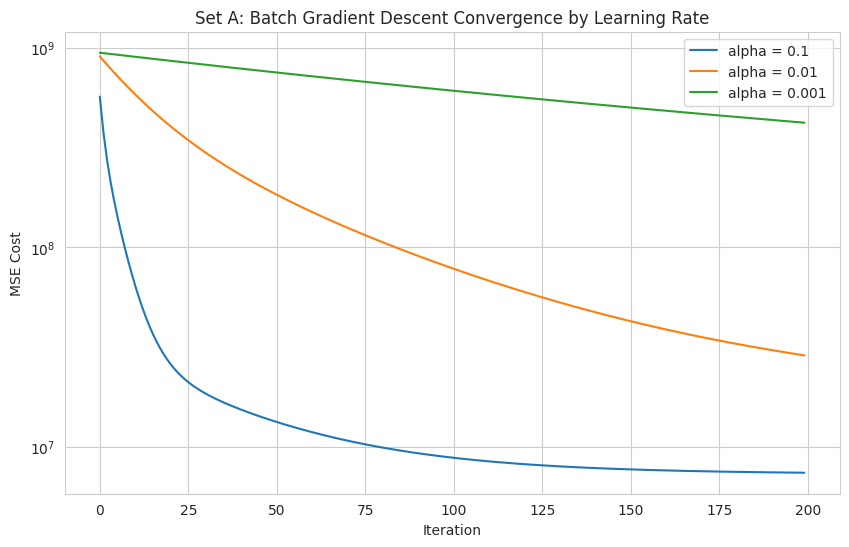

In [ ]:
# Convergence curves for varying learning rates
learning_rates = [0.1, 0.01, 0.001]
n_iters = 200

plt.figure(figsize=(10, 6))
for lr in learning_rates:
    _, cost_hist = batch_gradient_descent(X_A_train_b, y_train, lr, n_iters)
    plt.plot(range(n_iters), cost_hist, label=f'alpha = {lr}')

plt.title('Set A: Batch Gradient Descent Convergence by Learning Rate')
plt.xlabel('Iteration')
plt.ylabel('MSE Cost')
plt.yscale('log')
plt.legend()
plt.show()